# 07 · ST7789, SPI y actualización de la pantalla

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](06_hardware_y_medicion.ipynb) · [Siguiente](08_configuracion_compilacion_y_practicas.ipynb)

## SPI y controlador

La placa envía datos de forma síncrona por SPI. SCLK marca el ritmo y MOSI lleva los bits al controlador ST7789. CS identifica al periférico seleccionado. DC separa comandos de datos y RST reinicia el controlador. En el módulo, las etiquetas SDA y SCL del cableado corresponden a MOSI y SCLK. El controlador acepta comandos de configuración y bloques de píxeles. El proyecto no usa MISO, así que el programador no obtiene una confirmación de recepción del módulo.

En el entorno principal, TFT_eSPI usa HSPI a 20 MHz. El controlador y los GPIO se fijan con `include/TFT_Setup.h`, que PlatformIO incluye en la compilación. La variante de diagnóstico usa FSPI a 5 MHz con los mismos pines. `display.setRotation(1)` establece la orientación horizontal del monitor. Para la pantalla del proyecto el diagnóstico espera 320 × 240 en esa orientación. La resolución física depende del módulo.

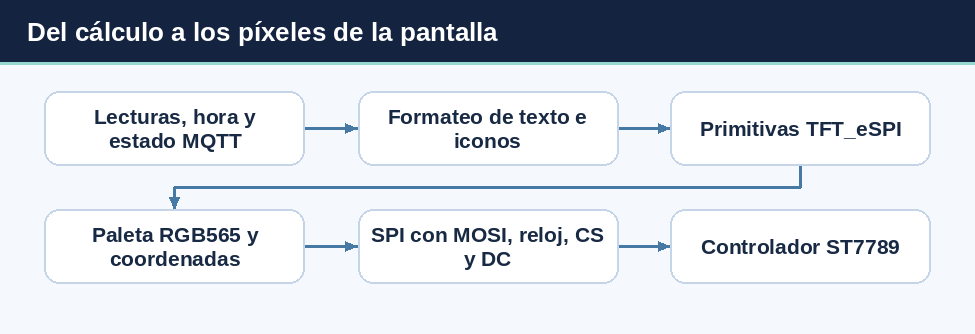

## Aritmética de píxeles

El dibujo usa coordenadas en la pantalla lógica que devuelve la biblioteca. La esquina superior izquierda se toma como origen. `x` crece hacia la derecha y `y` hacia abajo. `cardHeight()` resta el encabezado, espacios y pie a la altura de pantalla, y divide el espacio reservado entre tres indicadores. `cardCenter()` ubica cada tarjeta a partir de su índice.

`rgb565()` toma canales rojo, verde y azul de 8 bits y conserva respectivamente 5, 6 y 5 bits. `red & 0xF8` conserva los 5 bits altos de rojo. `green & 0xFC` conserva los 6 altos de verde. Los desplazamientos colocan cada canal en un entero de 16 bits. El termómetro, la gota y las líneas de gas se construyen con círculos, rectángulos, segmentos y triángulos. Las unidades acompañan el valor para distinguir °C, %RH y ppm.

## Distribución y actualizaciones

`drawDisplay()` trabaja al inicio. Dibuja fondo, encabezado, icono de reloj, separación, tarjetas y línea del pie. Las siguientes funciones mantienen cada parte de forma independiente.

| Función | Cuándo actúa | Qué muestra |
|---|---|---|
| `updateDisplay()` | Al terminar una muestra periódica, comparando con los textos anteriores. | Temperatura, humedad y gas. Las lecturas no finitas se ven como `--`. |
| `updateClock()` | Cuando cambia el segundo mostrado o se muestra la hora por primera vez. | Hora local en formato de 24 h y estado de sincronización. |
| `updateMqttStatus()` | En el primer dibujo y al cambiar el estado observado de MQTT. | Indicador y texto de conexión en el pie. |

Usar la alineación de texto y una zona de relleno evita que queden restos de una cifra larga al reemplazarla por una corta. Redibujar solo áreas cambiantes reduce el tráfico SPI y el parpadeo. El reloj muestra `ESPERANDO NTP` y `--:--:--` mientras el tiempo del sistema no pasa la validación. Una vez sincronizado usa el desplazamiento UTC−06:00 configurado en el firmware.

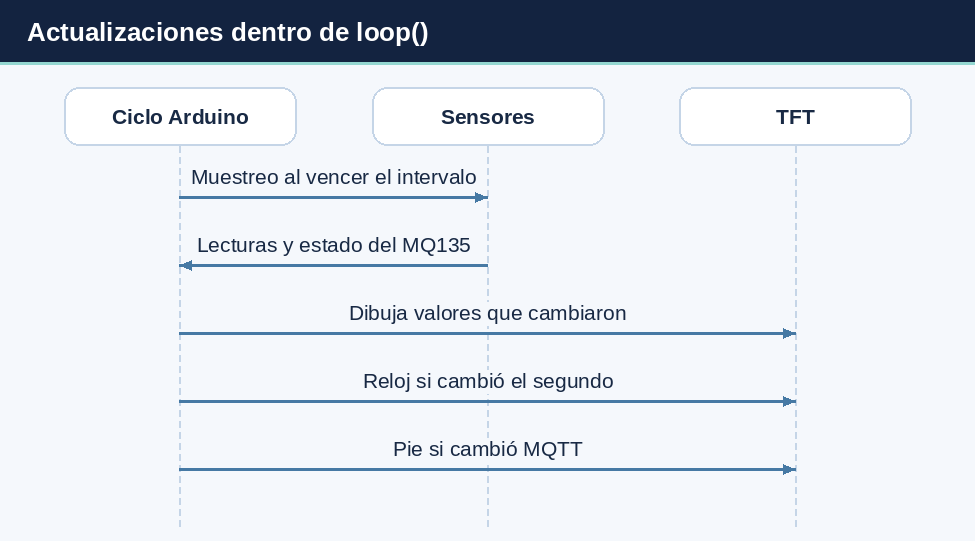

## Aislar un problema de pantalla

Abre la [prueba aislada de pantalla](prueba_pantalla.md) y revisa la [guía de configuración y carga](08_configuracion_compilacion_y_practicas.ipynb). Establece primero si hay imagen en la prueba de colores. Si la retroiluminación enciende y la imagen está vacía, revisa cableado y controlador. Distingue un reinicio completo de un redibujo observando la salida serie. La prueba aislada permite comparar una ejecución sin sensores y sin tareas de red. Para regresar al monitor normal vuelve a compilar y cargar el entorno principal.